找到 9 个共同文件
num123_-800_100_0_0007_depth.npy: MAE=0.0983 m, RMSE=0.1175 m, δ<1.25=0.9453
num123_-800_150_0_0008_depth.npy: MAE=0.0451 m, RMSE=0.0574 m, δ<1.25=1.0000
num123_-800_200_0_0009_depth.npy: MAE=0.0498 m, RMSE=0.0638 m, δ<1.25=0.9999
num123_-850_100_0_0004_depth.npy: MAE=0.0606 m, RMSE=0.0787 m, δ<1.25=1.0000
num123_-850_150_0_0005_depth.npy: MAE=0.0784 m, RMSE=0.0941 m, δ<1.25=0.9966
num123_-850_200_0_0006_depth.npy: MAE=0.0438 m, RMSE=0.0562 m, δ<1.25=1.0000
num123_-900_100_0_0001_depth.npy: MAE=0.0332 m, RMSE=0.0397 m, δ<1.25=1.0000
num123_-900_150_0_0002_depth.npy: MAE=0.0246 m, RMSE=0.0314 m, δ<1.25=1.0000
num123_-900_200_0_0003_depth.npy: MAE=0.0385 m, RMSE=0.0453 m, δ<1.25=1.0000

===== 平均结果 =====
MAE    : 0.0525 m
RMSE   : 0.0649 m
δ<1.25 : 0.9935 (99.35%)


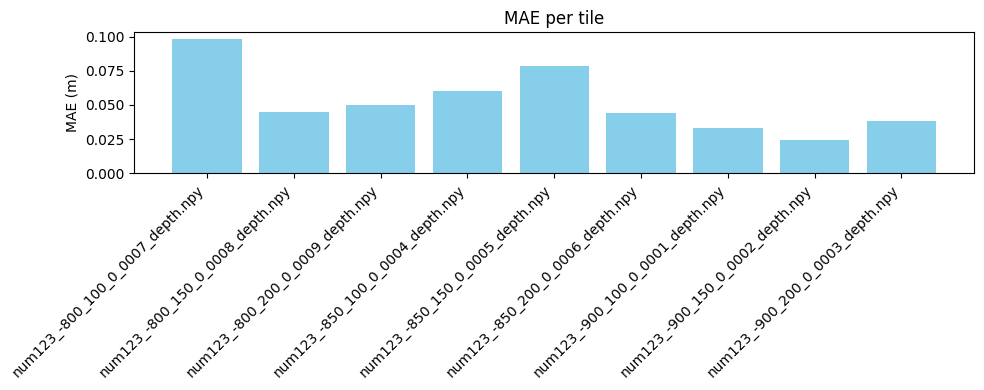

In [1]:
# ====================== 配置（直接修改这里的路径） ======================
SYNTH_DIR  = "/home/viplab/liukejia/project/result/inference_images_depth"      # 合成深度图文件夹
ORACLE_DIR = "/home/viplab/liukejia/project/result/render_3d_stitched_depth"            # 真实渲染深度图文件夹
IS_PNG     = False                              # 深度图是否以PNG存储（否则为.npy）
PNG_SCALE  = 256.0                              # 若为PNG，以此系数转换为米（如有缩放）
# =======================================================================

import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
%matplotlib inline

# ---------- 工具函数 ----------
def load_depth(path, is_png=False, scale=256.0):
    if path.endswith('.npy'):
        return np.load(path)
    elif path.endswith('.png'):
        img = Image.open(path)
        depth = np.array(img, dtype=np.float32)
        if is_png:
            depth /= scale
        return depth
    else:
        raise ValueError(f"不支持的文件格式: {path}")

def compute_metrics(pred, gt):
    mask = (pred > 0) & np.isfinite(pred) & (gt > 0) & np.isfinite(gt)
    p, g = pred[mask], gt[mask]
    if len(p) == 0:
        return np.nan, np.nan, np.nan
    mae  = np.mean(np.abs(p - g))
    rmse = np.sqrt(np.mean((p - g) ** 2))
    ratio = np.maximum(p / g, g / p)
    delta1 = np.mean(ratio < 1.25)
    return mae, rmse, delta1

# ---------- 主流程 ----------
synth_files = set(os.listdir(SYNTH_DIR))
oracle_files = set(os.listdir(ORACLE_DIR))
common = sorted(list(synth_files & oracle_files))
print(f"找到 {len(common)} 个共同文件")
if len(common) == 0:
    print("错误：两个文件夹中没有同名文件。")
    exit()

maes, rmses, deltas, fnames = [], [], [], []
for fname in common:
    p = load_depth(os.path.join(SYNTH_DIR, fname), IS_PNG, PNG_SCALE)
    g = load_depth(os.path.join(ORACLE_DIR, fname), IS_PNG, PNG_SCALE)
    if p.shape != g.shape:
        print(f"跳过 {fname}: 尺寸不一致 {p.shape} vs {g.shape}")
        continue
    m, r, d = compute_metrics(p, g)
    maes.append(m); rmses.append(r); deltas.append(d); fnames.append(fname)
    print(f"{fname}: MAE={m:.4f} m, RMSE={r:.4f} m, δ<1.25={d:.4f}")

if len(maes) == 0:
    print("没有有效数据。")
else:
    print("\n===== 平均结果 =====")
    print(f"MAE    : {np.nanmean(maes):.4f} m")
    print(f"RMSE   : {np.nanmean(rmses):.4f} m")
    print(f"δ<1.25 : {np.nanmean(deltas):.4f} ({np.nanmean(deltas)*100:.2f}%)")

    # 可选：绘制每张图的 MAE
    plt.figure(figsize=(10,4))
    plt.bar(fnames, maes, color='skyblue')
    plt.xticks(rotation=45, ha='right')
    plt.ylabel('MAE (m)')
    plt.title('MAE per tile')
    plt.tight_layout()
    plt.show()